In [1]:
import squigglepy as sq

from datetime import datetime
from pprint import pprint

from libs import run_model, plot_exponential_growth, analyze_agi_arrival, calculate_doubling_time
from model_params import start_task_length, agi_task_length, doubling_time, shift, current_best_date

print("Loaded libraries")

Loaded libraries


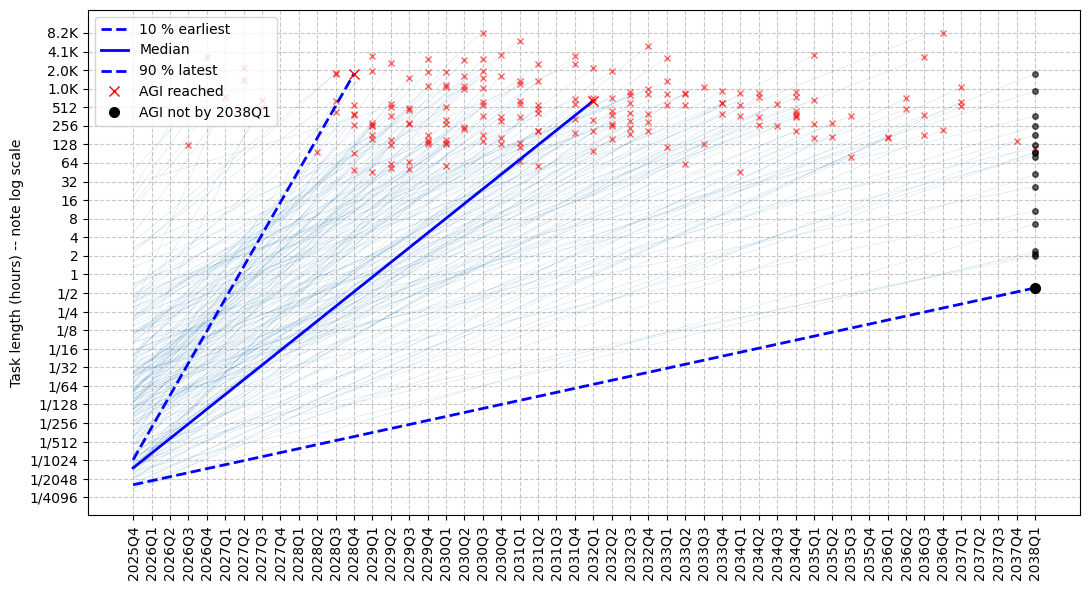

In [2]:
samples = plot_exponential_growth(
    doubling_time_days=doubling_time,
    start_hours=start_task_length,
    start_date=current_best_date,
    agi_task_length=agi_task_length,
    shift=shift,
    n_quarters=49,
    n_samples=100_000,
    n_traces=200,
    max_task_power=13,
    min_y_power=-15,
)

In [3]:
### UNDER CONSTRUCTION

"""
╔══════════════════════════════════════════════════════════╗
║                                                          ║
║                  UNDER CONSTRUCTION                      ║
║                                                          ║
║                      /\                                  ║
║                     /  \                                 ║
║                    / !! \                                ║
║                   /      \                               ║
║                  /   O    \                              ║
║                 /   /|\    \                             ║
║                /   / | \    \                            ║
║               /     _|_      \                           ║
║              /     / |        \                          ║
║             /     /  |         \                         ║
║            /    _/   |__        \                        ║
║           /    /        \        \                       ║
║          /    |          |________\                      ║
║         /     |         /           \                    ║
║        /______|________/─────────────\                   ║
║              Digging...                                  ║
║                                                          ║
║              PARDON OUR DUST                             ║
║                                                          ║
║        This part is currently being built!               ║
║          Please check back soon...                       ║
║                                                          ║
║                                                          ║
╚══════════════════════════════════════════════════════════╝
"""

'\n╔══════════════════════════════════════════════════════════╗\n║                                                          ║\n║                  UNDER CONSTRUCTION                      ║\n║                                                          ║\n║                      /\\                                  ║\n║                     /  \\                                 ║\n║                    / !! \\                                ║\n║                   /      \\                               ║\n║                  /   O    \\                              ║\n║                 /   /|\\    \\                             ║\n║                /   / | \\    \\                            ║\n║               /     _|_      \\                           ║\n║              /     / |        \\                          ║\n║             /     /  |         \\                         ║\n║            /    _/   |__        \\                        ║\n║           /    /        \\        \\                

In [4]:
# -----------
# ACCELERATION: Is the curve actually superexponential or subexponential? Does the doubling time itself change? Set the curve parameter.

print("\n\n")
print("## ACCELERATION")
acceleration = sq.mixture([
        [0.1, 1 + sq.lognorm(0.005, 0.1, credibility=80)],
        [0.8, 1],
        [0.1, 1 - sq.lognorm(0.005, 0.1, credibility=80)],
    ])
pprint(sq.get_percentiles(acceleration @ 100_000, digits=3))




## ACCELERATION
{1: 0.898,
 5: 0.977,
 10: 0.999,
 20: 1.0,
 30: 1.0,
 40: 1.0,
 50: 1.0,
 60: 1.0,
 70: 1.0,
 80: 1.0,
 90: 1.0,
 95: 1.021,
 99: 1.097}


In [5]:
def adapted_metr_model():
    start_task_length_ = start_task_length * (2 ** (shift / doubling_time))
    days = calculate_doubling_time(start_task_length_, agi_task_length, doubling_time)
    measurement_error_variance = sq.invlognorm(0.8, 1.5) # Add measurement error on tasks: SD fit to trend variance from Figure 12
    return days * measurement_error_variance

samples = run_model(adapted_metr_model, index_date=current_best_date, cores=4)
print('\n\n')
analyze_agi_arrival(samples)

Generating samples with 4 cores...


100%|███████████████████████████████████████████████████████████████████████████| 100000/100000 [00:29<00:00, 3422.37it/s]


Shuffling data...
Waiting for other cores...


100%|█████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:00<00:00, 2094.27it/s]


...Collected!
{1: 538,
 5: 869,
 10: 1092,
 20: 1441,
 30: 1755,
 40: 2066,
 50: 2401,
 60: 2772,
 70: 3244,
 80: 3905,
 90: 4991,
 95: 6129,
 99: 8949}

-

{1: '2027 Jun 02',
 5: '2028 Apr 28',
 10: '2028 Dec 07',
 20: '2029 Nov 21',
 30: '2030 Oct 02',
 40: '2031 Aug 08',
 50: '2032 Jul 09',
 60: '2033 Jul 15',
 70: '2034 Oct 30',
 80: '2036 Aug 21',
 90: '2039 Aug 11',
 95: '2042 Sep 23',
 99: '2050 Jun 12'}



## DISTRIBUTION OF AGI ARRIVAL DATE ##
1%: 2026.5
2%: 2026.8
3%: 2027.0
4%: 2027.2
5%: 2027.4
10%: 2028.0
15%: 2028.5
20%: 2028.9
25%: 2029.4
35%: 2030.3
50%: 2031.6
60%: 2032.6
75%: 2034.7
80%: 2035.7
90%: 2038.7
95%: 2041.8


## DISTRIBUTION OF RELATIVE AGI ARRIVAL DATE ##
1%: 1.5 years from now
2%: 1.8 years from now
3%: 2.0 years from now
4%: 2.2 years from now
5%: 2.4 years from now
10%: 3.0 years from now
15%: 3.5 years from now
20%: 3.9 years from now
25%: 4.4 years from now
35%: 5.3 years from now
50%: 6.6 years from now
60%: 7.6 years from now
75%: 9.7 years from now